研究問題 2：各站點的電輔車使用比例與時間型態可以分成哪幾類？

In [1]:
import sys
import json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity
from youbike import station_hour_counts, prepare_stations, STUDY_MONTHS, SEED

# 中文字型（Windows 用微軟正黑體，找不到就用預設字型）
plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "Noto Sans CJK TC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

INTERIM = ROOT / "data" / "interim"
EXTERNAL = ROOT / "data" / "external"

## 建構站點使用矩陣

研究期間為 2026 年 3–6 月（`STUDY_MONTHS`）。`station_hour_counts` 一次只讀一個月，結果是長表：站點 × 平日／假日 × 小時 × 車種的借車次數。

In [2]:
counts = station_hour_counts(INTERIM, months=STUDY_MONTHS)
counts.head()

,rent_station,day_type,rent_hour,bike_type,n
0,一壽橋,holiday,0,ebike,1
1,一壽橋,holiday,0,regular,14
2,一壽橋,holiday,1,regular,4
3,一壽橋,holiday,2,ebike,1
4,一壽橋,holiday,2,regular,1


每列一個站點，欄位為平日／假日 × 24 小時的電輔車借車比例。

In [3]:
wide = counts.pivot_table(index=["rent_station", "day_type", "rent_hour"],
                          columns="bike_type", values="n", fill_value=0, observed=True)
wide["ebike_share"] = wide["ebike"] / (wide["ebike"] + wide["regular"])
ebike_share = wide["ebike_share"].unstack(["day_type", "rent_hour"])
ebike_share.shape

(1724, 48)

## 步驟 1：篩選站點與處理稀疏時段

電輔車比例 = 電輔車借車數 ÷ 總借車數。借車數太少時，這個比例很不穩定（例如只有 3 次借車，比例只能是 0、33%、67% 或 100%），會讓 PCA 和分群被雜訊主導。所以分三步處理：

1. **排除總借車量太少的站點**：4 個月總借車數低於 `STATION_MIN` 的站。
2. **合併深夜時段**：00–05 時借車很少，合併成一個時段，欄位從 48 欄（2 × 24）變成 38 欄（2 × 19）。
3. **處理剩下的稀疏格子**：借車數低於 `CELL_MIN` 的格子，用該站同一日別（平日或假日）的整體電輔車比例代替。

門檻放在下面的參數，改了之後重跑即可。

In [4]:
STATION_MIN = 2000   # 站點 4 個月總借車數下限
CELL_MIN = 10        # 單一格子（站點 × 日別 × 時段）借車數下限
NIGHT_HOURS = range(0, 6)  # 合併成「深夜」的小時

### 1-1 站點總借車量分布

count      1724.0
mean      16205.0
std       15054.0
min          22.0
1%          967.0
5%         2309.0
10%        3572.0
25%        6608.0
50%       11824.0
max      187781.0
Name: n, dtype: float64
總借車數 <   500：   8 站
總借車數 < 1,000：  20 站
總借車數 < 2,000：  66 站
總借車數 < 4,000： 213 站


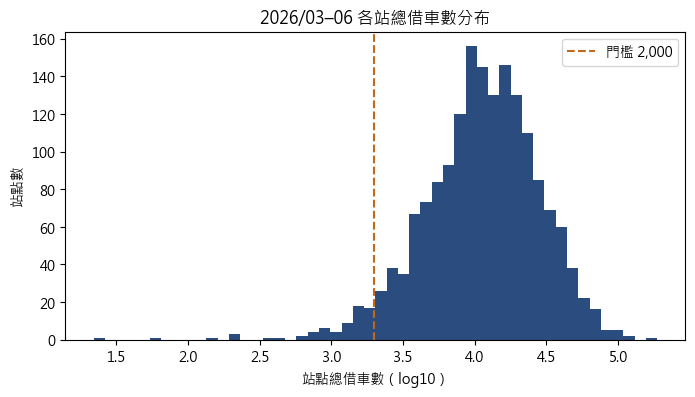

In [5]:
station_total = counts.groupby("rent_station", observed=True)["n"].sum()
print(station_total.describe(percentiles=[.01, .05, .10, .25, .5]).round(0))

for t in [500, 1000, 2000, 4000]:
    print(f"總借車數 < {t:>5,}：{(station_total < t).sum():>4} 站")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(np.log10(station_total), bins=50, color="#2B4C7E")
ax.axvline(np.log10(STATION_MIN), color="#C2681B", ls="--", label=f"門檻 {STATION_MIN:,}")
ax.set_xlabel("站點總借車數（log10）")
ax.set_ylabel("站點數")
ax.set_title("2026/03–06 各站總借車數分布")
ax.legend()
plt.show()

### 1-2 各時段的稀疏程度

每個時段中，借車數不到 `CELL_MIN` 的站點比例。深夜（約 01–05 時）明顯偏高，這就是要合併深夜時段的原因。

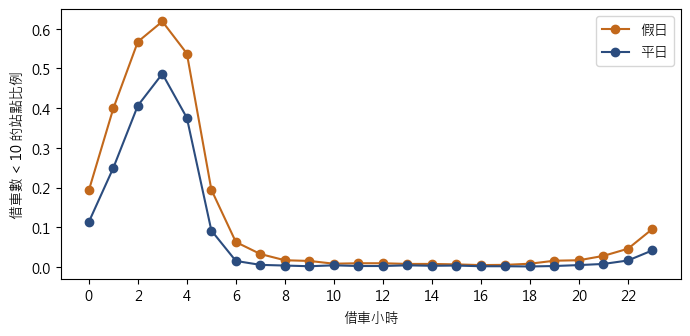

In [6]:
cell_n = (counts.groupby(["rent_station", "day_type", "rent_hour"], observed=True)["n"].sum()
          .unstack(["day_type", "rent_hour"]).fillna(0))
sparse_by_hour = (cell_n < CELL_MIN).mean().unstack("day_type")

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(sparse_by_hour.columns, ["#C2681B", "#2B4C7E"]):
    ax.plot(sparse_by_hour.index.astype(int), sparse_by_hour[col], marker="o", color=color, label={"weekday": "平日", "holiday": "假日"}[col])
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("借車小時")
ax.set_ylabel(f"借車數 < {CELL_MIN} 的站點比例")
ax.legend()
plt.show()

### 1-3 套用篩選，建立分析矩陣 `X`

In [7]:
c = counts.copy()
c["rent_hour"] = c["rent_hour"].astype(int)
c["block"] = np.where(c["rent_hour"].isin(NIGHT_HOURS), "00-05", c["rent_hour"].map("{:02d}".format))

# 1. 排除總借車量太少的站點
keep = station_total.index[station_total >= STATION_MIN]
c = c[c["rent_station"].isin(keep)]

# 2. 合併深夜時段後，計算每格的電輔車數與總數
g = (c.pivot_table(index=["rent_station", "day_type", "block"], columns="bike_type",
                   values="n", aggfunc="sum", fill_value=0, observed=True))
g["total"] = g["ebike"] + g["regular"]
share = (g["ebike"] / g["total"]).unstack(["day_type", "block"])
n_cell = g["total"].unstack(["day_type", "block"]).reindex(columns=share.columns).fillna(0)

# 3. 稀疏格子用該站同日別的整體比例代替
day_share = (g.groupby(level=["rent_station", "day_type"])[["ebike", "total"]].sum()
             .eval("ebike / total").unstack("day_type"))
fallback = pd.DataFrame({col: day_share[col[0]] for col in share.columns}, index=share.index)
sparse = (n_cell < CELL_MIN) | share.isna()
X = share.mask(sparse, fallback)
X.columns = [f"{d}_{b}" for d, b in X.columns]
X = X[sorted(X.columns, key=lambda s: (s.split("_")[0] != "weekday", s))]  # 平日在前

print(f"站點：{len(station_total):,} → {len(X):,}（排除 {len(station_total) - len(X)} 站，總借車數 < {STATION_MIN:,}）")
print(f"欄位：{X.shape[1]}（平日、假日各 {X.shape[1] // 2} 個時段）")
print(f"被替代的稀疏格子：{sparse.values.sum():,} 格（{sparse.values.mean():.1%}），涉及 {sparse.any(axis=1).sum()} 站")
print(f"剩餘缺值：{X.isna().sum().sum()}")

站點：1,724 → 1,658（排除 66 站，總借車數 < 2,000）
欄位：38（平日、假日各 19 個時段）
被替代的稀疏格子：426 格（0.7%），涉及 162 站
剩餘缺值：0


### 1-4 檢查被排除的站點與停用站

被排除的站點大多是新設站或位置偏遠的站。`act = 0` 是 stations.json 下載當下（2026/11）停用的站，研究期間可能仍在營運，所以先保留，只列出來供討論。

In [8]:
raw = pd.DataFrame(json.load(open(EXTERNAL / "stations.json", encoding="utf-8")))
stations = prepare_stations(raw)
stations["act"] = pd.to_numeric(raw["act"], errors="coerce").values
stations = stations.set_index("name")

dropped = station_total[station_total < STATION_MIN].sort_values()
print("被排除的站點（依行政區）：")
print(stations.reindex(dropped.index)["district"].value_counts(dropna=False).to_string())

inactive = X.index[X.index.map(stations["act"]).fillna(1) == 0]
print(f"\n保留的站點中，目前停用（act = 0）的有 {len(inactive)} 站：", list(inactive))

被排除的站點（依行政區）：
district
內湖區    24
士林區    12
北投區    10
文山區     8
南港區     4
萬華區     3
中正區     2
大同區     1
大安區     1
中山區     1

保留的站點中，目前停用（act = 0）的有 15 站： ['世新大學(試院路)', '八仙里辦公處', '劍潭基河路口', '南京一江街口', '南京新生路口', '富民路145巷口', '復華花園新城', '林安泰古厝', '洛陽停車場', '臺大原分所北側', '臺科大側門(基隆路四段73巷)', '薇閣高中', '農安雙城街口', '通河東街福港街262巷口', '長春龍江路口']


### 1-5 篩選後的描述統計

各時段電輔車比例的平均與四分位距。

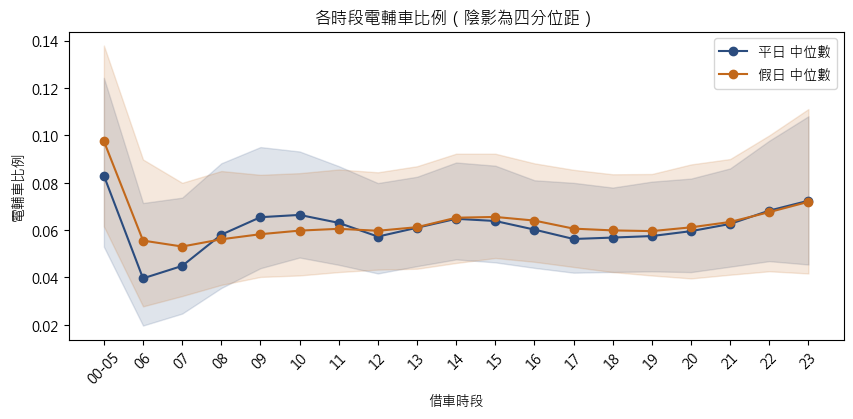

已存成 data/processed/station_ebike_share.parquet


In [9]:
desc = X.describe().T[["mean", "25%", "50%", "75%"]]
fig, ax = plt.subplots(figsize=(10, 4))
for prefix, color, label in [("weekday", "#2B4C7E", "平日"), ("holiday", "#C2681B", "假日")]:
    d = desc[desc.index.str.startswith(prefix)]
    x = d.index.str.split("_").str[1]
    ax.plot(x, d["50%"], marker="o", color=color, label=f"{label} 中位數")
    ax.fill_between(x, d["25%"], d["75%"], color=color, alpha=0.15)
ax.set_xlabel("借車時段")
ax.set_ylabel("電輔車比例")
ax.set_title("各時段電輔車比例（陰影為四分位距）")
ax.legend()
plt.xticks(rotation=45)
plt.show()

X.to_parquet(ROOT / "data" / "processed" / "station_ebike_share.parquet")
print("已存成 data/processed/station_ebike_share.parquet")

## 步驟 2：主成分分析（PCA）

### 兩種版本

1-5 的圖顯示，站與站之間「整體電輔車比例高低」的差異，比各時段之間的起伏大很多。若直接做 PCA，第一主成分幾乎一定是整體高低，時間型態會被壓到後面。因此做兩個版本：

| 版本 | 矩陣 | 回答的問題 |
|---|---|---|
| A：原始比例 | `X` | 哪些站電輔車用得多或少，以及在哪些時段 |
| B：列中心化 | `X` 每列減去該站的平均比例 | 不管整體高低，哪些站在特定時段特別愛用電輔車 |

38 個變數都是比例、單位相同，所以用共變異數矩陣（不標準化），保留各時段原本的變異大小。

### 2-1 適合度檢定：KMO 與 Bartlett 球形檢定

Bartlett 檢定的虛無假設是「相關矩陣為單位矩陣」（變數之間沒有相關），需要拒絕才適合做 PCA。KMO 大於 0.8 表示適合。

版本 B 每列總和為 0，相關矩陣是奇異矩陣，無法計算 KMO；它是 `X` 的線性轉換，以版本 A 的檢定結果為準。

In [10]:
chi2, p_value = calculate_bartlett_sphericity(X)
kmo_per_var, kmo_total = calculate_kmo(X)
print(f"Bartlett 球形檢定：χ² = {chi2:,.0f}，df = {X.shape[1] * (X.shape[1] - 1) // 2}，p = {p_value:.2g}")
print(f"KMO（整體）= {kmo_total:.3f}")
print(f"KMO（各變數）範圍：{kmo_per_var.min():.3f}–{kmo_per_var.max():.3f}")

Bartlett 球形檢定：χ² = 45,902，df = 703，p = 0
KMO（整體）= 0.979
KMO（各變數）範圍：0.930–0.990


C:\Users\USERYA\AppData\Local\Programs\Python\Python313\Lib\site-packages\factor_analyzer\utils.py:244: UserWarning: The inverse of the variance-covariance matrix was calculated using the Moore-Penrose generalized matrix inversion, due to its determinant being at or very close to zero.
  warnings.warn(


### 2-2 配適 PCA 與平行分析

用三個準則決定保留幾個主成分：

- **陡坡圖（scree plot）**：找曲線轉折處。
- **累積解釋變異**：參考 80%。
- **平行分析（Horn, 1965）**：把每一欄各自隨機打亂、破壞變數間的相關後再做 PCA，重複 `N_PERM` 次；只保留特徵值大於隨機資料第 95 百分位的主成分。這是三者中最客觀的準則。

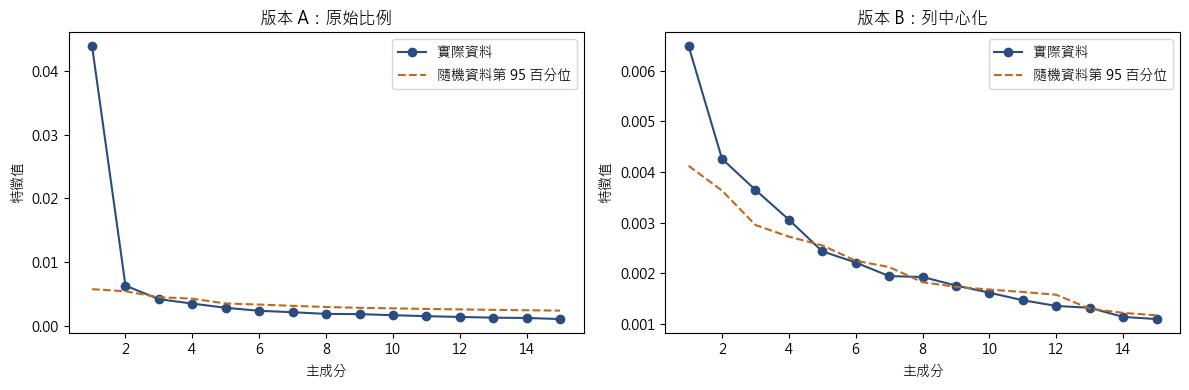

,PC1,PC2,PC3,前 3 個累積,達 80% 需要,平行分析保留
版本,,,,,,
A：原始比例,47.0%,6.8%,4.5%,58.3%,13,2
B：列中心化,13.0%,8.5%,7.3%,28.7%,20,4


In [11]:
N_PERM = 50
rng = np.random.default_rng(SEED)

level = X.mean(axis=1).rename("level")      # 各站整體電輔車比例（版本 B 被移除的部分）
versions = {"A：原始比例": X, "B：列中心化": X.sub(level, axis=0)}

def parallel_analysis(M, n_perm=N_PERM):
    """隨機打亂每一欄後的特徵值第 95 百分位。"""
    vals = M.to_numpy()
    sims = []
    for _ in range(n_perm):
        shuffled = np.column_stack([rng.permutation(vals[:, j]) for j in range(vals.shape[1])])
        sims.append(PCA().fit(shuffled).explained_variance_)
    return np.percentile(sims, 95, axis=0)

pcas, summary = {}, []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, M) in zip(axes, versions.items()):
    pca = PCA().fit(M)
    ev = pca.explained_variance_
    pa = parallel_analysis(M)
    k_pa = int(np.argmax(ev <= pa))           # 第一個不超過隨機門檻的位置
    ratio = pca.explained_variance_ratio_
    pcas[name] = pca
    summary.append({"版本": name, "PC1": f"{ratio[0]:.1%}", "PC2": f"{ratio[1]:.1%}", "PC3": f"{ratio[2]:.1%}",
                    "前 3 個累積": f"{ratio[:3].sum():.1%}", "達 80% 需要": int(np.argmax(ratio.cumsum() >= 0.8) + 1),
                    "平行分析保留": k_pa})
    n_show = 15
    ax.plot(range(1, n_show + 1), ev[:n_show], marker="o", color="#2B4C7E", label="實際資料")
    ax.plot(range(1, n_show + 1), pa[:n_show], ls="--", color="#C2681B", label="隨機資料第 95 百分位")
    ax.set_title(f"版本 {name}")
    ax.set_xlabel("主成分")
    ax.set_ylabel("特徵值")
    ax.legend()
plt.tight_layout()
plt.show()

pd.DataFrame(summary).set_index("版本")

### 2-3 負荷量：各主成分代表什麼時間型態

把每個主成分的負荷量畫成 24 小時曲線（平日、假日各一條）。負荷量為正的時段，代表該主成分分數高的站，在這些時段電輔車比例較高。

主成分的正負號是任意的，解讀時看曲線的「形狀」即可。

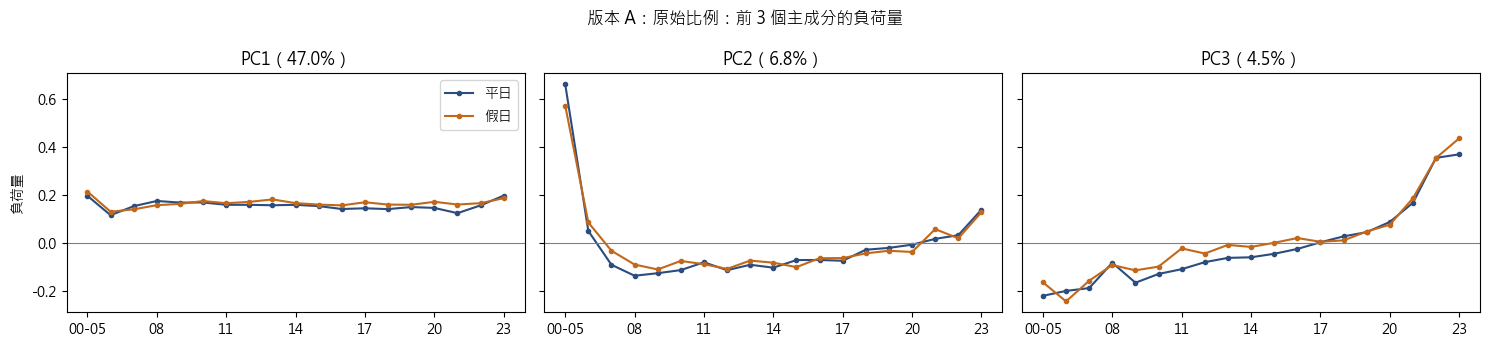

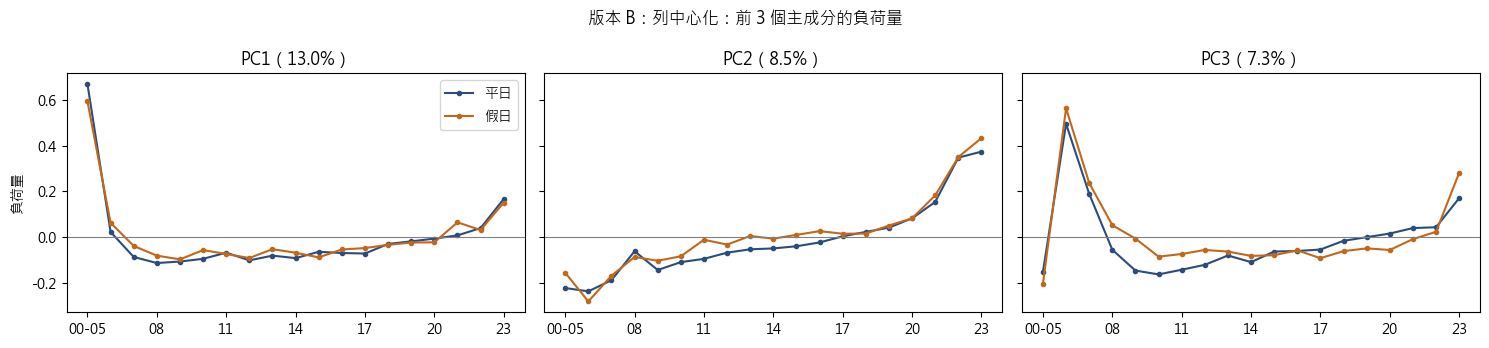

In [12]:
N_PC = 3   # 先畫前 3 個主成分；依 2-2 的平行分析結果調整

blocks = [c.split("_")[1] for c in X.columns if c.startswith("weekday")]
for name, pca in pcas.items():
    fig, axes = plt.subplots(1, N_PC, figsize=(5 * N_PC, 3.5), sharey=True)
    for i, ax in enumerate(axes):
        load = pd.Series(pca.components_[i], index=X.columns)
        for prefix, color, label in [("weekday", "#2B4C7E", "平日"), ("holiday", "#C2681B", "假日")]:
            ax.plot(blocks, load[[f"{prefix}_{b}" for b in blocks]].values, marker="o", ms=3, color=color, label=label)
        ax.axhline(0, color="grey", lw=0.8)
        ax.set_title(f"PC{i + 1}（{pca.explained_variance_ratio_[i]:.1%}）")
        ax.set_xticks(range(0, len(blocks), 3))
        ax.set_xticklabels(blocks[::3])
    axes[0].set_ylabel("負荷量")
    axes[0].legend()
    fig.suptitle(f"版本 {name}：前 {N_PC} 個主成分的負荷量")
    plt.tight_layout()
    plt.show()

### 2-4 敏感度檢查：深夜時段是否主導結果

00–05 時段的借車數最少，比例的抽樣誤差最大，變異也最大，可能讓某個主成分只是在反映深夜的雜訊。這裡計算深夜兩欄對各主成分的貢獻，並在移除深夜欄位後重做 PCA，看主成分是否穩定。

In [13]:
night_cols = [c for c in X.columns if c.endswith("00-05")]
X_wo = X.drop(columns=night_cols)
versions_wo = {"A：原始比例": X_wo, "B：列中心化": X_wo.sub(X_wo.mean(axis=1), axis=0)}
rows = []
for name in versions:
    pca_wo = PCA(n_components=N_PC).fit(versions_wo[name])
    for i in range(N_PC):
        load = pd.Series(pcas[name].components_[i], index=X.columns)
        night_contrib = (load[night_cols] ** 2).sum()       # 負荷量平方和 = 該欄位的貢獻比例
        a = load.drop(night_cols).to_numpy()
        sims = [abs(np.corrcoef(a, pca_wo.components_[j])[0, 1]) for j in range(N_PC)]
        rows.append({"版本": name, "主成分": f"PC{i + 1}", "深夜兩欄的貢獻": f"{night_contrib:.0%}",
                     "移除深夜後最相似主成分": f"PC{int(np.argmax(sims)) + 1}", "負荷量相關": round(max(sims), 2)})
pd.DataFrame(rows).set_index(["版本", "主成分"])

深夜兩欄的貢獻 移除深夜後最相似主成分  負荷量相關
版本     主成分                           
A：原始比例 PC1      8%         PC1   1.00
       PC2     76%         PC2   0.83
       PC3      7%         PC2   0.95
B：列中心化 PC1     80%         PC1   0.86
       PC2      7%         PC1   0.95
       PC3      6%         PC2   0.97

### 2-5 儲存主成分分數

兩個版本的主成分分數與各站整體比例 `level` 存在一起，下一步分群直接讀這個檔。

In [14]:
scores = [level]
for name, pca in pcas.items():
    tag = name[0]
    s = pd.DataFrame(pca.transform(versions[name])[:, :N_PC], index=X.index,
                     columns=[f"{tag}_PC{i + 1}" for i in range(N_PC)])
    scores.append(s)
scores = pd.concat(scores, axis=1)
scores.to_parquet(ROOT / "data" / "processed" / "station_pca_scores.parquet")
print(f"已存成 data/processed/station_pca_scores.parquet：{scores.shape}")
scores.describe().round(3)

已存成 data/processed/station_pca_scores.parquet：(1658, 7)


,level,A_PC1,A_PC2,A_PC3,B_PC1,B_PC2,B_PC3
count,1658.000,1658.000,1658.000,1658.000,1658.000,1658.000,1658.000
mean,0.072,-0.000,-0.000,-0.000,0.000,0.000,-0.000
std,0.034,0.209,0.080,0.065,0.081,0.065,0.060
min,0.015,-0.357,-0.594,-0.302,-0.528,-0.288,-0.336
25%,0.053,-0.117,-0.043,-0.037,-0.048,-0.038,-0.033
50%,0.065,-0.043,-0.006,-0.001,-0.009,-0.001,-0.004
75%,0.082,0.061,0.038,0.035,0.037,0.034,0.029
max,0.479,2.564,0.515,0.321,0.549,0.313,0.312


### 2-6 結果解讀（2026/03–06，STATION_MIN = 2000）

**適合度**：Bartlett χ² = 45,902（df = 703，p < .001），KMO = 0.979（各變數 0.930–0.990），非常適合做 PCA。

**版本 A（原始比例）**：平行分析保留 2 個主成分。

- PC1（47.0%）：所有時段負荷量皆為正且大小相近，代表**整體電輔車比例高低**（size component）。分數最高的站為金湖路 347 巷 125 弄口（電輔車占 48%）、天母公園、溫泉路 81 號、文湖街 21 巷 118 弄口，多位於山坡地，與 RQ3 的假設 H3 方向一致。
- PC2（6.8%）：76% 的變異來自 00–05 時段，代表**深夜偏好電輔車**的程度。

**版本 B（列中心化，只看時間型態）**：平行分析保留 4 個主成分，但前 3 個合計只解釋 28.7%，表示扣除整體高低後，站與站之間的時間型態差異較分散。

- PC1（13.0%）：以 00–05 時段為主（貢獻 80%）。
- PC2（8.5%）：晚間 21–23 時為正、清晨 06–07 時為負，代表**晚間型 vs. 清晨型**。
- PC3（7.3%）：清晨 06–07 時特別高，代表**清晨偏好電輔車**。

**敏感度**：移除深夜欄位後，版本 A 的 PC1 不變（負荷量相關 1.00），其餘主成分的相關介於 0.83–0.97，結構大致穩定。但深夜時段借車少、抽樣誤差大，深夜相關的主成分需謹慎解讀。

**對分群的意涵**：版本 A 的 PC1 由少數極端站（電輔車比例 > 25%）拉開，分群前需決定是否處理離群值。

## 步驟 3：分群（K-means、階層式）與 MDS

### 分群用的變數

不直接用 38 欄比例分群，因為歐氏距離會被「整體電輔車比例高低」主導（2-6 的版本 A PC1 占 47%）。改用以下變數，讓「用量高低」與「時間型態」都有份量：

| 變數 | 來源 | 理由 |
|---|---|---|
| `log_level` | 各站整體電輔車比例取對數 | `level` 嚴重右偏（偏態約 3.1），少數山坡站會把群拉開；取對數後偏態約 0.1 |
| `B_PC2`–`B_PC4` | 版本 B（列中心化）的主成分分數 | 平行分析保留 4 個；`B_PC1` 有 80% 來自 00–05 時段（2-4），借車數少、雜訊大，所以不放 |

處理步驟：每個變數在第 1、99 百分位截尾（winsorize，減少離群站的影響，但所有站仍會被分群），再標準化成 z 分數，讓四個變數權重相同。

In [15]:
CLUSTER_PCS = [2, 3, 4]   # 版本 B 用來分群的主成分
CLIP_Q = 0.01             # 截尾百分位
K_RANGE = range(2, 9)     # 候選群數
N_BOOT = 50               # bootstrap 次數

pca_B = pcas["B：列中心化"]
B_scores = pd.DataFrame(pca_B.transform(versions["B：列中心化"]), index=X.index)
feat = pd.concat([np.log(level).rename("log_level"),
                  B_scores[[i - 1 for i in CLUSTER_PCS]].set_axis([f"B_PC{i}" for i in CLUSTER_PCS], axis=1)], axis=1)
print(f"level 偏態：{level.skew():.2f} → log 後 {np.log(level).skew():.2f}")

feat_clip = feat.clip(feat.quantile(CLIP_Q), feat.quantile(1 - CLIP_Q), axis=1)
F = (feat_clip - feat_clip.mean()) / feat_clip.std()
print(f"分群矩陣 F：{F.shape}")
F.corr().round(2)

level 偏態：3.10 → log 後 0.13
分群矩陣 F：(1658, 4)


,log_level,B_PC2,B_PC3,B_PC4
log_level,1.00,0.08,-0.11,0.15
B_PC2,0.08,1.00,-0.02,0.01
B_PC3,-0.11,-0.02,1.00,0.01
B_PC4,0.15,0.01,0.01,1.00


### 3-1 選擇群數

三個準則：

- **輪廓係數（silhouette）**：每站與自己群的距離相對於最近他群的距離，介於 −1 到 1，越大表示群分得越開。分別算 K-means 與 Ward 階層式分群。
- **群內平方和（elbow）**：K-means 的 inertia，找轉折處。
- **Bootstrap 穩定度**：從站點中有放回抽樣 `N_BOOT` 次，每次重新跑 K-means，再把所有站分到新的群中心，與完整資料的分群比較調整後 Rand 指數（ARI）。ARI 越接近 1 表示分群越不受抽樣影響。

另外列出 K-means 與 Ward 兩種方法的 ARI，看兩種演算法是否得到相似的群。

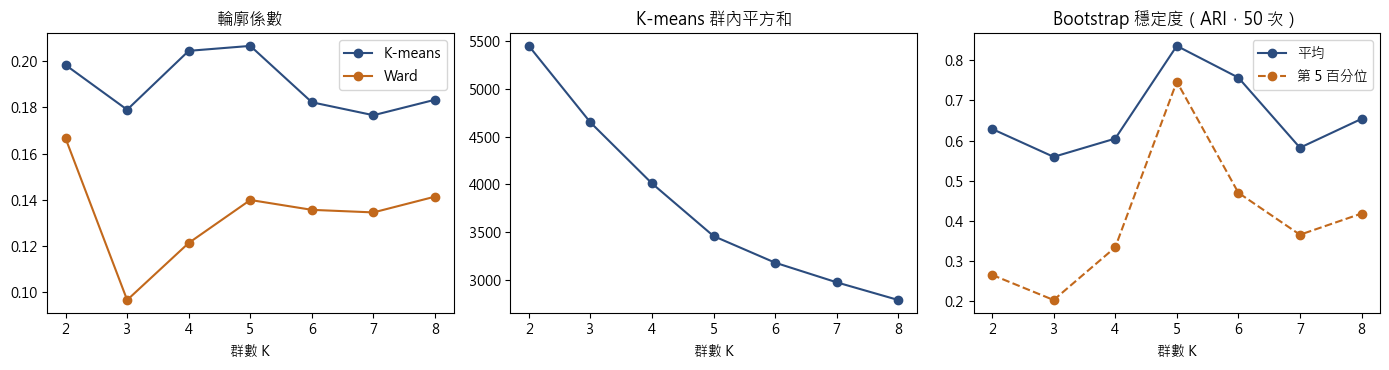

,K-means 輪廓,Ward 輪廓,inertia,K-means vs Ward ARI,bootstrap ARI 平均,bootstrap ARI 第 5 百分位,最小群站數
K,,,,,,,
2,0.198,0.167,5449.160,0.056,0.629,0.265,623
3,0.179,0.097,4648.807,0.201,0.559,0.203,299
4,0.204,0.121,4010.368,0.275,0.605,0.334,248
5,0.207,0.140,3459.627,0.363,0.836,0.747,203
6,0.182,0.136,3181.260,0.293,0.757,0.470,177
7,0.177,0.135,2975.675,0.236,0.582,0.365,119
8,0.183,0.141,2790.658,0.228,0.654,0.418,109


In [16]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

Fv = F.to_numpy()
boot_rng = np.random.default_rng(SEED)
rows = []
for k in K_RANGE:
    km = KMeans(k, n_init=20, random_state=SEED).fit(Fv)
    ward = AgglomerativeClustering(k, linkage="ward").fit_predict(Fv)
    aris = []
    for b in range(N_BOOT):
        idx = boot_rng.integers(0, len(Fv), len(Fv))
        boot = KMeans(k, n_init=5, random_state=b).fit(Fv[idx])
        aris.append(adjusted_rand_score(km.labels_, boot.predict(Fv)))
    rows.append({"K": k, "K-means 輪廓": silhouette_score(Fv, km.labels_), "Ward 輪廓": silhouette_score(Fv, ward),
                 "inertia": km.inertia_, "K-means vs Ward ARI": adjusted_rand_score(km.labels_, ward),
                 "bootstrap ARI 平均": np.mean(aris), "bootstrap ARI 第 5 百分位": np.percentile(aris, 5),
                 "最小群站數": np.bincount(km.labels_).min()})
k_table = pd.DataFrame(rows).set_index("K")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(k_table.index, k_table["K-means 輪廓"], marker="o", color="#2B4C7E", label="K-means")
axes[0].plot(k_table.index, k_table["Ward 輪廓"], marker="o", color="#C2681B", label="Ward")
axes[0].set_title("輪廓係數"); axes[0].legend()
axes[1].plot(k_table.index, k_table["inertia"], marker="o", color="#2B4C7E")
axes[1].set_title("K-means 群內平方和")
axes[2].plot(k_table.index, k_table["bootstrap ARI 平均"], marker="o", color="#2B4C7E", label="平均")
axes[2].plot(k_table.index, k_table["bootstrap ARI 第 5 百分位"], marker="o", ls="--", color="#C2681B", label="第 5 百分位")
axes[2].set_title(f"Bootstrap 穩定度（ARI，{N_BOOT} 次）"); axes[2].legend()
for ax in axes:
    ax.set_xlabel("群數 K")
plt.tight_layout()
plt.show()
k_table.round(3)

### 3-2 Ward 階層式分群樹狀圖

只畫最後 30 次合併。虛線是切成 `K` 群的高度。

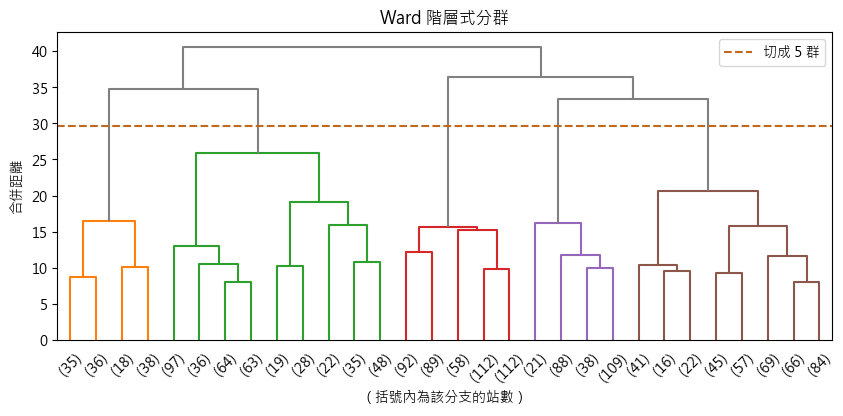

In [17]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

K = 5   # 依 3-1 選定：輪廓係數最高、bootstrap 最穩定

Z = linkage(Fv, method="ward")
cut = (Z[-K, 2] + Z[-K + 1, 2]) / 2
fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, color_threshold=cut, above_threshold_color="grey")
ax.axhline(cut, color="#C2681B", ls="--", label=f"切成 {K} 群")
ax.set_xlabel("（括號內為該分支的站數）")
ax.set_ylabel("合併距離")
ax.set_title("Ward 階層式分群")
ax.legend()
plt.show()

### 3-3 最終分群與穩定度

以 K-means（`K` 群）為最終結果。為了讓群的編號有意義，依各群整體電輔車比例由低到高重新編號為 1 到 `K`。

各群的穩定度用 bootstrap **Jaccard 係數**（Hennig, 2007）：每次 bootstrap 找與原本某群重疊最多的新群，計算 Jaccard 係數，再取平均。一般以 > 0.75 為穩定、0.6–0.75 為有一定型態、< 0.5 為不穩定。

In [18]:
km = KMeans(K, n_init=50, random_state=SEED).fit(Fv)
order = pd.Series(level.values).groupby(km.labels_).mean().sort_values().index   # 依 level 由低到高
relabel = {old: new + 1 for new, old in enumerate(order)}
cluster = pd.Series([relabel[l] for l in km.labels_], index=X.index, name="cluster")

ward_labels = fcluster(Z, K, criterion="maxclust")
print(f"K-means 與 Ward 的 ARI：{adjusted_rand_score(cluster, ward_labels):.2f}")
print(pd.crosstab(cluster, pd.Series(ward_labels, index=X.index, name="Ward")).to_string())

def jaccard_stability(Fv, labels, k, n_boot=N_BOOT, seed=SEED):
    rng_j = np.random.default_rng(seed)
    out = np.zeros((n_boot, k))
    for b in range(n_boot):
        idx = rng_j.integers(0, len(Fv), len(Fv))
        boot = KMeans(k, n_init=5, random_state=b).fit(Fv[idx]).predict(Fv)
        for c in range(1, k + 1):
            a = labels == c
            out[b, c - 1] = max((a & (boot == j)).sum() / (a | (boot == j)).sum() for j in range(k))
    return out.mean(axis=0)

sil = silhouette_samples(Fv, cluster)
stab = pd.DataFrame({"站數": cluster.value_counts().sort_index(),
                     "平均輪廓": pd.Series(sil, index=X.index).groupby(cluster).mean(),
                     "bootstrap Jaccard": jaccard_stability(Fv, cluster.to_numpy(), K)})
stab.round(3)

K-means 與 Ward 的 ARI：0.36
Ward       1    2    3    4    5
cluster                         
1          1  107  405    4  121
2         12   45   35  226   16
3        109   36   23    0   65
4          5  187    0    1   10
5          0   37    0   25  188


,站數,平均輪廓,bootstrap Jaccard
cluster,,,
1,638,0.271,0.881
2,334,0.194,0.886
3,233,0.145,0.886
4,203,0.151,0.907
5,250,0.161,0.842


### 3-4 各群的特徵

表格：各群在分群變數上的平均 z 分數。圖一：各群在平日、假日各時段的電輔車比例（中位數）。圖二：扣除各站整體比例後的時間型態。用來命名各群。

,站數,level 中位數,log_level,B_PC2,B_PC3,B_PC4
cluster,,,,,,
1,638,0.05,-0.84,-0.14,0.01,-0.01
2,334,0.07,0.33,0.76,-0.46,-0.92
3,233,0.07,0.35,-0.82,1.40,-0.41
4,203,0.09,0.73,1.09,0.41,1.42
5,250,0.08,0.76,-0.78,-1.07,0.50


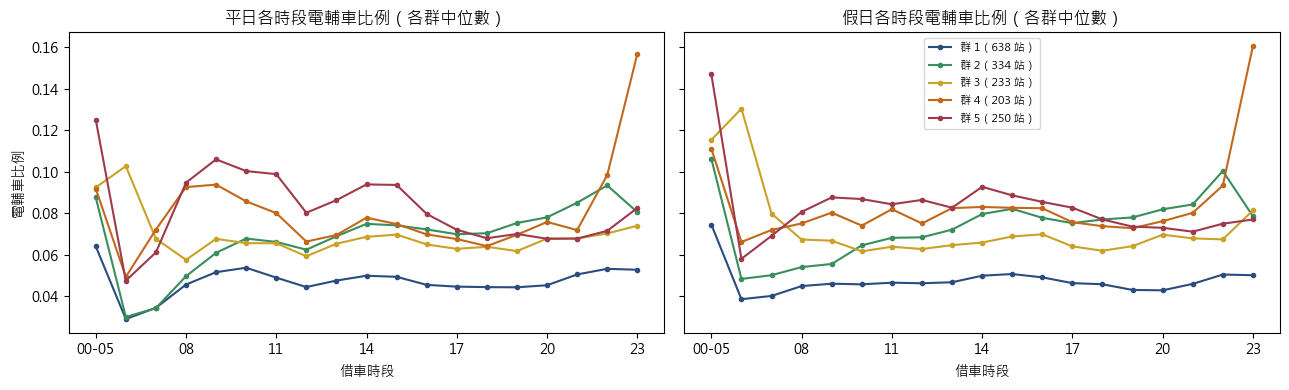

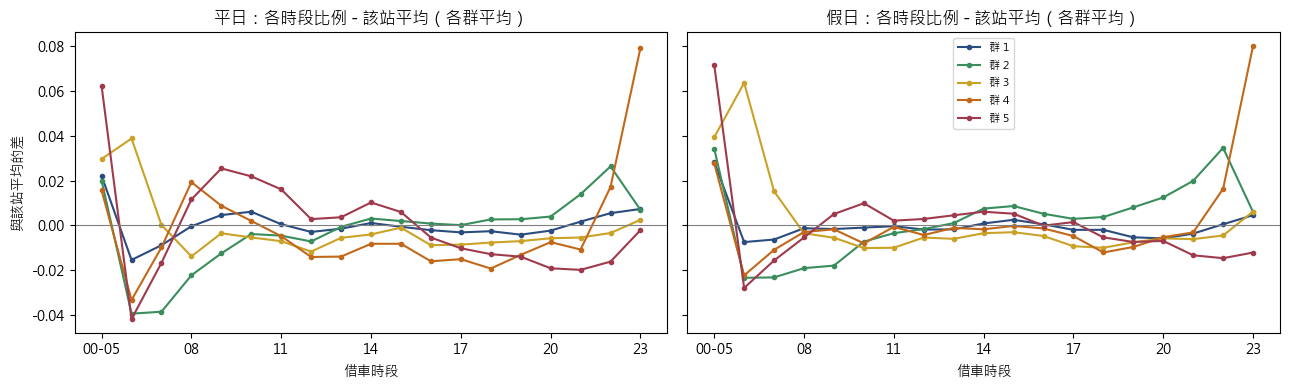

In [19]:
PALETTE = ["#2B4C7E", "#3A8D5C", "#C9A227", "#C2681B", "#9E3A4C", "#6B4C9A", "#4A9DB0", "#7F7F7F"]
colors = {c: PALETTE[c - 1] for c in range(1, K + 1)}

profile = F.groupby(cluster).mean()
profile.insert(0, "level 中位數", level.groupby(cluster).median())
profile.insert(0, "站數", cluster.value_counts().sort_index())
display(profile.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (prefix, title) in zip(axes, [("weekday", "平日"), ("holiday", "假日")]):
    for c in range(1, K + 1):
        med = X.loc[cluster == c, [f"{prefix}_{b}" for b in blocks]].median()
        ax.plot(blocks, med.values, marker="o", ms=3, color=colors[c], label=f"群 {c}（{(cluster == c).sum()} 站）")
    ax.set_title(f"{title}各時段電輔車比例（各群中位數）")
    ax.set_xticks(range(0, len(blocks), 3))
    ax.set_xticklabels(blocks[::3])
    ax.set_xlabel("借車時段")
axes[0].set_ylabel("電輔車比例")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# 列中心化後的形狀：扣除各站整體比例，只看時間型態
Xc = versions["B：列中心化"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (prefix, title) in zip(axes, [("weekday", "平日"), ("holiday", "假日")]):
    for c in range(1, K + 1):
        avg = Xc.loc[cluster == c, [f"{prefix}_{b}" for b in blocks]].mean()
        ax.plot(blocks, avg.values, marker="o", ms=3, color=colors[c], label=f"群 {c}")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(f"{title}：各時段比例 - 該站平均（各群平均）")
    ax.set_xticks(range(0, len(blocks), 3))
    ax.set_xticklabels(blocks[::3])
    ax.set_xlabel("借車時段")
axes[0].set_ylabel("與該站平均的差")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 3-5 各群的代表站與空間分布

代表站：各群中最接近群中心的 5 站。地圖用站點經緯度，檢查各群是否有空間聚集（第 4 步 CA 與 C 部分會進一步分析）。

               cluster level district
rent_station                         
辛亥新生路口東南側            1  4.5%      大安區
景美污水抽水站              1  4.4%      文山區
永吉公園                 1  5.1%      信義區
萬華安居社會住宅B區           1  5.4%      萬華區
建國南路一段279巷口          1  5.4%      大安區
捷運市政府站(3號出口)         2  7.2%      信義區
臺北市立美術館_1            2  7.0%      中山區
台北護理大學               2  7.4%      北投區
長安林森路口公車站            2  8.2%      中山區
福林路100巷11弄口          2  7.3%      士林區
環河南雙園街口              3  7.0%      萬華區
新生長春路口               3  8.1%      中山區
吉林路407巷口             3  7.4%      中山區
吉林農安街口(西北側)          3  7.2%      中山區
內湖區農會                3  8.2%      內湖區
南港路三段130巷口           4  9.6%      南港區
蘭興公園                 4  9.7%      士林區
舊莊區民活動中心             4  7.6%      南港區
樟樹公園                 4  8.9%      文山區
捷運大直站(3號出口)_1        4  7.7%      中山區
永安藝文館_表演36房          5  9.9%      文山區
捷運北投站(1號出口)          5  9.5%      北投區
忠順區民活動中心             5  9.6%      文山區
港墘路1巷口               5  7.8%      內湖區
大直街94巷      

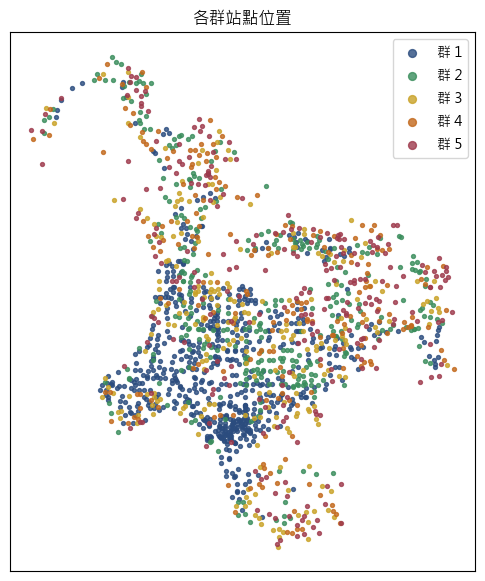

沒有經緯度的站：0


In [20]:
dist_to_center = np.linalg.norm(Fv - km.cluster_centers_[km.labels_], axis=1)
rep = (pd.DataFrame({"cluster": cluster, "dist": dist_to_center, "level": level})
       .sort_values("dist").groupby("cluster").head(5).sort_values(["cluster", "dist"]))
rep["district"] = rep.index.map(stations["district"])
print(rep.assign(level=rep["level"].map("{:.1%}".format)).drop(columns="dist").to_string())

geo = stations.reindex(X.index)[["lat", "lng"]]
fig, ax = plt.subplots(figsize=(7, 7))
for c in range(1, K + 1):
    g_c = geo[cluster == c]
    ax.scatter(g_c["lng"], g_c["lat"], s=8, color=colors[c], label=f"群 {c}", alpha=0.8)
ax.set_aspect(1 / np.cos(np.deg2rad(25.05)))
ax.set_title("各群站點位置")
ax.legend(markerscale=2)
ax.set_xticks([]); ax.set_yticks([])
plt.show()
print(f"沒有經緯度的站：{geo['lat'].isna().sum()}")

### 3-6 MDS：站點間距離的二維呈現

以分群變數 `F` 的歐氏距離做計量 MDS（SMACOF），檢查各群在二維平面上是否分得開。用 Kruskal stress-1 評估配適：< 0.1 良好、0.1–0.2 尚可、> 0.2 差，此時二維圖只能看大致趨勢。Shepard 圖比較原始距離與 MDS 距離（隨機抽 5,000 對）。

計算約需 1 分鐘。

Kruskal stress-1 = 0.224


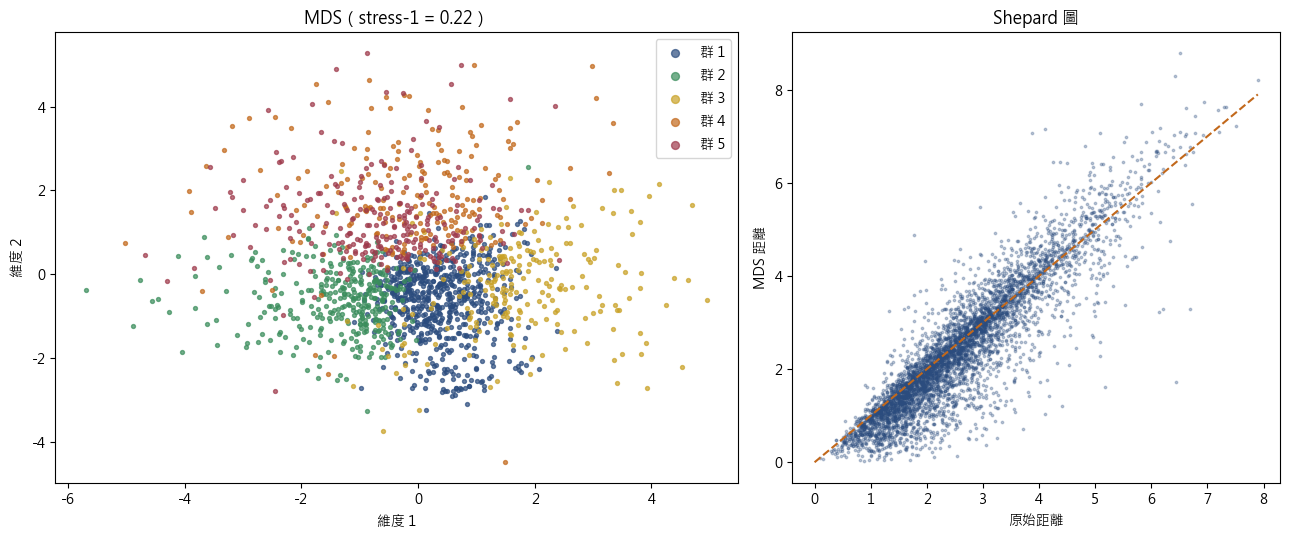

In [21]:
from sklearn.manifold import MDS
from scipy.spatial.distance import pdist

mds = MDS(n_components=2, random_state=SEED, n_init=1, max_iter=200, normalized_stress="auto")
Y = mds.fit_transform(Fv)
d_orig, d_mds = pdist(Fv), pdist(Y)
stress1 = np.sqrt(((d_orig - d_mds) ** 2).sum() / (d_orig ** 2).sum())
print(f"Kruskal stress-1 = {stress1:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})
for c in range(1, K + 1):
    axes[0].scatter(Y[cluster == c, 0], Y[cluster == c, 1], s=8, alpha=0.7, color=colors[c], label=f"群 {c}")
axes[0].set_title(f"MDS（stress-1 = {stress1:.2f}）")
axes[0].set_xlabel("維度 1"); axes[0].set_ylabel("維度 2")
axes[0].legend(markerscale=2)
pick = np.random.default_rng(SEED).choice(len(d_orig), 5000, replace=False)
axes[1].scatter(d_orig[pick], d_mds[pick], s=3, alpha=0.3, color="#2B4C7E")
lim = d_orig[pick].max()
axes[1].plot([0, lim], [0, lim], color="#C2681B", ls="--")
axes[1].set_xlabel("原始距離"); axes[1].set_ylabel("MDS 距離")
axes[1].set_title("Shepard 圖")
plt.tight_layout()
plt.show()

### 3-7 儲存分群結果

存成 `data/processed/station_clusters.parquet`，供第 4 步 CA 與 C 部分使用。

In [22]:
out = pd.concat([cluster, level, feat, F.add_suffix("_z")], axis=1)
out["district"] = out.index.map(stations["district"])
out[["mds1", "mds2"]] = Y
out.to_parquet(ROOT / "data" / "processed" / "station_clusters.parquet")
print(f"已存成 data/processed/station_clusters.parquet：{out.shape}")
out.head()

已存成 data/processed/station_clusters.parquet：(1658, 13)


,cluster,level,log_level,B_PC2,B_PC3,B_PC4,log_level_z,B_PC2_z,B_PC3_z,B_PC4_z,district,mds1,mds2
rent_station,,,,,,,,,,,,,
一壽橋,5,0.069855,-2.661340,-0.046870,-0.069029,-0.012499,0.130893,-0.756854,-1.209657,-0.233252,文山區,-0.946697,0.367422
一江公園,1,0.050564,-2.984520,-0.055364,-0.004948,-0.050726,-0.698994,-0.894429,-0.089082,-0.973392,中山區,0.459426,-1.312633
一江南京東路口(西南側),2,0.050627,-2.983273,0.047774,-0.037789,-0.044953,-0.695793,0.776166,-0.663364,-0.861622,中山區,-0.895819,-1.175638
三合街一段82巷62弄口,5,0.071045,-2.644446,-0.030533,-0.036876,0.013726,0.174276,-0.492223,-0.647401,0.274504,北投區,-0.178749,0.480853
三張犁,1,0.055377,-2.893598,-0.019835,-0.008266,-0.001137,-0.465519,-0.318946,-0.147100,-0.013267,信義區,0.215505,-0.293590


### 3-8 結果解讀（2026/03–06，K = 5）

**群數**：K = 5 的 K-means 輪廓係數最高（0.207），bootstrap 也最穩定（ARI 平均 0.84，第 5 百分位 0.75；其他 K 都在 0.76 以下）。各群的 bootstrap Jaccard 介於 0.84–0.91，都算穩定。

**但群與群之間沒有明顯界線**：輪廓係數只有 0.2 左右（> 0.5 才算結構清楚），K-means 與 Ward 的 ARI 只有 0.36，MDS 的 stress-1 = 0.22 也偏高。站點的使用型態比較像連續變化，5 群是把連續的空間切成穩定、可解讀的區塊，而不是自然分開的類別。報告時應這樣說明。

| 群 | 站數 | 電輔車比例中位數 | 時間型態（與該站平均比較） | 命名 | 主要行政區 |
|---|---|---|---|---|---|
| 1 | 638 | 5.1% | 各時段都接近平均，曲線平坦 | 低比例平穩型 | 大安 133、中正 93、中山 77、臺大校區 58 |
| 2 | 334 | 7.2% | 晚間 21–22 時較高（+1.4 至 +3.5 個百分點），清晨 06–07 時較低 | 晚間型 | 內湖 55、中山 43、北投 38 |
| 3 | 233 | 7.3% | 清晨 06 時特別高（平日 +3.9、假日 +6.4） | 清晨型 | 中山 39、士林 29、文山 27 |
| 4 | 203 | 8.5% | 23 時特別高（平日、假日都約 +8），平日 16–19 時較低 | 深夜 23 時型 | 士林 33、內湖 32 |
| 5 | 250 | 8.3% | 平日上午 09–11 時較高，晚間 20–22 時較低 | 日間型 | 內湖 68、北投 27、士林 27 |

**重點**：

- 第 1 群與其他群的差別主要在**整體比例高低**；第 2–5 群的整體比例相近（中位數 7–8.5%），差別在**哪個時段比較愛用電輔車**。
- 第 1 群集中在大安、中正、中山與臺大校區等市中心平地，第 4、5 群則多在內湖、士林、北投。電輔車比例最高的站（金湖路 347 巷 125 弄口 48%、天母公園 38%、溫泉路 81 號 31%）都在第 4、5 群，且位於山坡地，與 RQ3 的假設 H3 方向一致，留給 C 部分用坡度資料檢驗。
- 第 4 群 23 時的高峰很明顯，但原因還不清楚（可能和夜間一般車調度或站點車輛組成有關），解讀前應先確認是否為資料或營運因素造成。
- 00–05 時段沒有放進分群變數，但第 5 群在深夜的比例也較高（+6 至 +7），解讀時仍需注意深夜樣本少。

## 步驟 4：對應分析（CA）：行政區 × 站點類型

步驟 3 的地圖顯示各群在空間上並非隨機分布。這裡用行政區 × 群別的列聯表，先以卡方檢定確認兩者是否獨立，再用對應分析（CA）把行政區與群別畫在同一張圖上，看哪些行政區偏向哪些站點類型。

「臺大公館校區」在站點資料中是獨立的 `sarea`，但位於大安區，且只有 60 站、幾乎全屬第 1 群，單獨放會主導 CA 的某一維，所以併入大安區（`MERGE_CAMPUS`）。

In [23]:
from scipy.stats import chi2_contingency

MERGE_CAMPUS = True
CLUSTER_NAMES = {1: "1 低比例平穩", 2: "2 晚間", 3: "3 清晨", 4: "4 23時", 5: "5 日間"}

district = out["district"].replace({"臺大公館校區": "大安區"}) if MERGE_CAMPUS else out["district"]
N = pd.crosstab(district, cluster.map(CLUSTER_NAMES))
N.columns.name, N.index.name = "群別", "行政區"
display(N.assign(合計=N.sum(axis=1)))

chi2_stat, p_chi, dof, expected = chi2_contingency(N)
n_total = N.to_numpy().sum()
cramers_v = np.sqrt(chi2_stat / (n_total * (min(N.shape) - 1)))
print(f"卡方獨立性檢定：χ² = {chi2_stat:.1f}，df = {dof}，p = {p_chi:.2g}")
print(f"Cramér's V = {cramers_v:.3f}")
print(f"期望次數 < 5 的格子：{(expected < 5).sum()} / {expected.size}")

群別,1 低比例平穩,2 晚間,3 清晨,4 23時,5 日間,合計
行政區,,,,,,
中山區,77,43,39,18,20,197
中正區,93,16,14,4,6,133
信義區,42,35,23,10,15,125
內湖區,19,55,20,32,68,194
北投區,15,38,8,20,27,108
南港區,24,25,16,23,23,111
士林區,17,31,29,33,27,137
大同區,43,13,13,4,9,82
大安區,191,34,18,11,11,265


卡方獨立性檢定：χ² = 480.1，df = 44，p = 1.1e-74
Cramér's V = 0.269
期望次數 < 5 的格子：0 / 60


### 4-1 標準化殘差

標準化殘差 =（觀察次數 − 期望次數）/ √期望次數。絕對值大於 2 的格子（約 5% 顯著水準）代表該行政區的這類站明顯偏多（正）或偏少（負）。CA 的總慣量就是這些殘差平方和除以總站數。

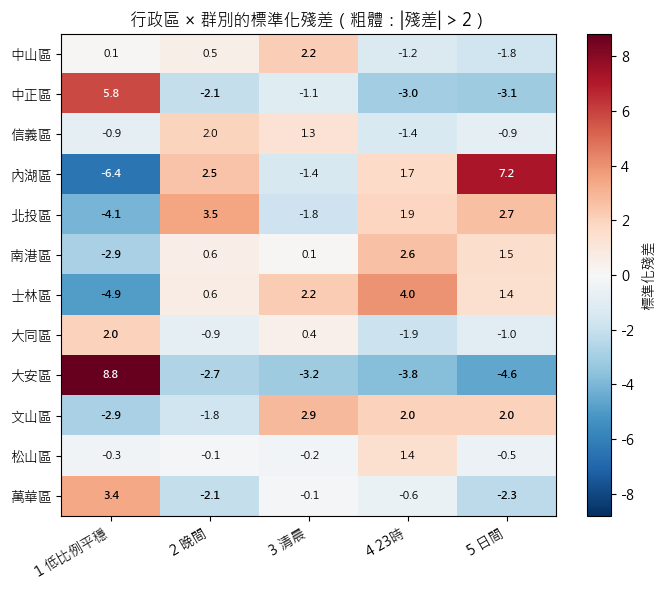

In [24]:
resid = (N - expected) / np.sqrt(expected)
fig, ax = plt.subplots(figsize=(7, 6))
lim = np.abs(resid.to_numpy()).max()
im = ax.imshow(resid, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(N.shape[1]), N.columns, rotation=30, ha="right")
ax.set_yticks(range(N.shape[0]), N.index)
for i in range(N.shape[0]):
    for j in range(N.shape[1]):
        v = resid.iat[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > lim * 0.6 else "black", fontweight="bold" if abs(v) > 2 else "normal")
fig.colorbar(im, ax=ax, label="標準化殘差")
ax.set_title("行政區 × 群別的標準化殘差（粗體：|殘差| > 2）")
plt.tight_layout()
plt.show()

### 4-2 對應分析

以奇異值分解（SVD）計算：令 $P = N / n$，列邊際 $r$、行邊際 $c$，對標準化殘差矩陣 $S = D_r^{-1/2}(P - rc^\top)D_c^{-1/2}$ 做 SVD，$S = U\Sigma V^\top$。

- 各維的主慣量 = $\sigma_k^2$，總慣量 = $\chi^2 / n$。
- 列（行政區）主座標 $F = D_r^{-1/2}U\Sigma$，行（群別）主座標 $G = D_c^{-1/2}V\Sigma$。
- 最多 $\min(I, J) - 1 = 4$ 維。

In [25]:
P = N.to_numpy() / n_total
r, c_mass = P.sum(axis=1), P.sum(axis=0)
S = (P - np.outer(r, c_mass)) / np.sqrt(np.outer(r, c_mass))
U, sv, Vt = np.linalg.svd(S, full_matrices=False)
n_dim = min(N.shape) - 1
U, sv, Vt = U[:, :n_dim], sv[:n_dim], Vt[:n_dim]

inertia = sv ** 2
ca_table = pd.DataFrame({"主慣量": inertia, "比例": inertia / inertia.sum(),
                         "累積比例": (inertia / inertia.sum()).cumsum()},
                        index=[f"維度 {k + 1}" for k in range(n_dim)])
print(f"總慣量 = {inertia.sum():.4f}（= χ²/n = {chi2_stat / n_total:.4f}）")
display(ca_table.round(3))

row_coord = pd.DataFrame(U * sv / np.sqrt(r)[:, None], index=N.index, columns=[f"Dim{k + 1}" for k in range(n_dim)])
col_coord = pd.DataFrame(Vt.T * sv / np.sqrt(c_mass)[:, None], index=N.columns, columns=row_coord.columns)

def ca_quality(coord, mass):
    """貢獻度（該點對該維慣量的貢獻）與 cos²（該維對該點的代表程度）。"""
    ctr = (coord ** 2).mul(mass, axis=0) / inertia
    cos2 = (coord ** 2).div((coord ** 2).sum(axis=1), axis=0)
    return pd.concat({"質量": pd.DataFrame({"": mass}, index=coord.index),
                      "貢獻度": ctr.iloc[:, :2], "cos²": cos2.iloc[:, :2],
                      "前兩維 cos²": pd.DataFrame({"": cos2.iloc[:, :2].sum(axis=1)})}, axis=1)

print("行政區：")
display(ca_quality(row_coord, r).round(3))
print("群別：")
display(ca_quality(col_coord, c_mass).round(3))

總慣量 = 0.2896（= χ²/n = 0.2896）


,主慣量,比例,累積比例
維度 1,0.242,0.835,0.835
維度 2,0.027,0.094,0.929
維度 3,0.013,0.044,0.973
維度 4,0.008,0.027,1.000


行政區：


質量    貢獻度          cos²        前兩維 cos²
             Dim1   Dim2   Dim1   Dim2         
行政區                                            
中山區  0.119  0.003  0.077  0.115  0.358    0.473
中正區  0.080  0.145  0.005  0.991  0.004    0.995
信義區  0.075  0.000  0.004  0.016  0.020    0.036
內湖區  0.117  0.220  0.274  0.849  0.119    0.968
北投區  0.065  0.082  0.160  0.762  0.168    0.930
南港區  0.067  0.039  0.003  0.899  0.007    0.907
士林區  0.083  0.095  0.163  0.809  0.156    0.965
大同區  0.049  0.020  0.001  0.840  0.006    0.846
大安區  0.160  0.312  0.084  0.963  0.029    0.992
文山區  0.067  0.034  0.206  0.494  0.334    0.828
松山區  0.064  0.000  0.005  0.077  0.089    0.167
萬華區  0.054  0.048  0.020  0.901  0.041    0.942

群別：


質量    貢獻度          cos²        前兩維 cos²
                 Dim1   Dim2   Dim1   Dim2         
群別                                                 
1 低比例平穩  0.385  0.563  0.017  0.993  0.003    0.997
2 晚間     0.201  0.063  0.126  0.590  0.131    0.721
3 清晨     0.141  0.011  0.628  0.123  0.781    0.903
4 23時    0.122  0.128  0.075  0.784  0.052    0.836
5 日間     0.151  0.234  0.154  0.870  0.064    0.934

### 4-3 對稱圖（symmetric biplot）

行政區與群別都用主座標。同類點之間的距離可直接比較（例如兩個行政區越近，群別組成越像）；行政區與群別之間只能看「方向」：行政區落在某群別的同一側，表示該行政區這類站偏多。點的大小代表質量（站數比例）。

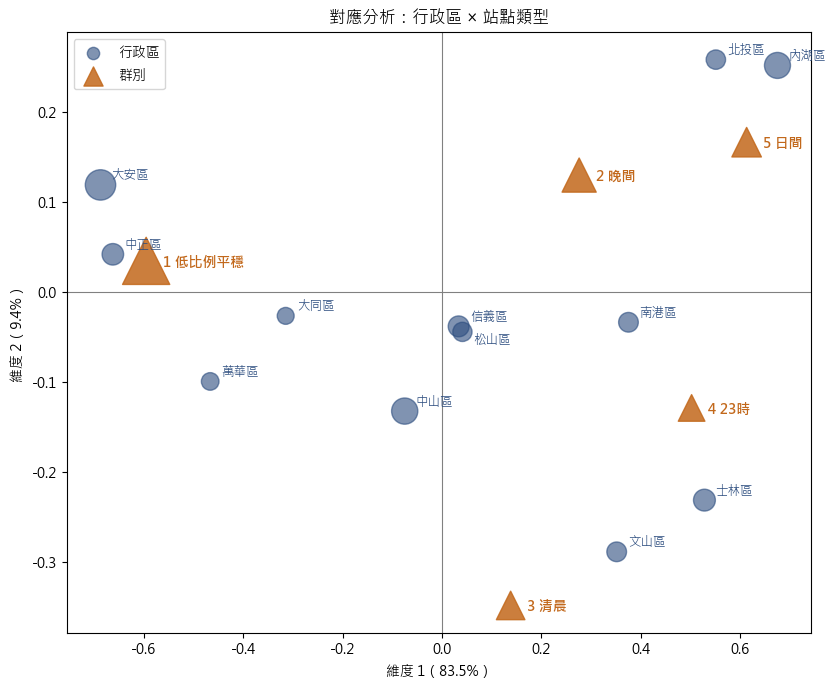

In [26]:
fig, ax = plt.subplots(figsize=(8.5, 7))
ax.axhline(0, color="grey", lw=0.8); ax.axvline(0, color="grey", lw=0.8)
ax.scatter(row_coord["Dim1"], row_coord["Dim2"], s=r * 3000, color="#2B4C7E", alpha=0.6, label="行政區")
placed = []
for name, (x, y) in row_coord[["Dim1", "Dim2"]].sort_values("Dim2", ascending=False).iterrows():
    close = sum(abs(x - px) < 0.08 and abs(y - py) < 0.03 for px, py in placed)   # 避免標籤重疊
    ax.annotate(name, (x, y), xytext=(8, 4 - 13 * close), textcoords="offset points", fontsize=9, color="#2B4C7E")
    placed.append((x, y))
ax.scatter(col_coord["Dim1"], col_coord["Dim2"], s=c_mass * 3000, marker="^", color="#C2681B", alpha=0.85, label="群別")
for name, (x, y) in col_coord[["Dim1", "Dim2"]].iterrows():
    ax.annotate(name, (x, y), xytext=(12, -4), textcoords="offset points", fontsize=10, color="#C2681B", fontweight="bold")
ax.set_xlabel(f"維度 1（{ca_table.iloc[0]['比例']:.1%}）")
ax.set_ylabel(f"維度 2（{ca_table.iloc[1]['比例']:.1%}）")
ax.set_title("對應分析：行政區 × 站點類型")
ax.legend(loc="best", markerscale=0.5)
plt.tight_layout()
plt.show()

### 4-4 結果解讀

**行政區與站點類型明顯相關**：卡方 χ² = 480.1（df = 44，p < .001），所有格子的期望次數都 ≥ 5，檢定有效。Cramér's V = 0.27，屬於中度關聯：行政區能說明一部分站點類型的差異，但同一區內仍有各種類型的站。

**CA 維度**：總慣量 0.290，前兩維解釋 92.9%，二維圖足以呈現主要結構。

- **維度 1（83.5%）：市中心 vs. 外圍**。負向是第 1 群（低比例平穩型，對維度 1 的貢獻 56%）與大安、中正、萬華、大同；正向是第 5 群（日間型）、第 4 群（23 時型）與內湖、北投、士林、南港、文山。這一維基本上就是「整體電輔車比例高低」在地理上的呈現：市中心平地的站電輔車用得少，外圍與山邊的站用得多。
- **維度 2（9.4%）：外圍各區之間的時間型態差異**。正向是內湖、北投與第 5 群（日間型）、第 2 群（晚間型）；負向是士林、文山與第 3 群（清晨型，對維度 2 的貢獻 63%）、第 4 群（23 時型）。

**標準化殘差的重點**（|殘差| > 2）：

| 行政區 | 偏多的群 | 偏少的群 |
|---|---|---|
| 大安 | 1 低比例平穩（+8.8） | 2、3、4、5 |
| 中正 | 1 低比例平穩（+5.8） | 2、4、5 |
| 萬華 | 1 低比例平穩（+3.4） | 2、5 |
| 內湖 | 5 日間（+7.2）、2 晚間（+2.5） | 1 |
| 北投 | 2 晚間（+3.5）、5 日間（+2.7） | 1 |
| 士林 | 4 23 時（+4.0）、3 清晨（+2.2） | 1 |
| 文山 | 3 清晨（+2.9）、4、5 | 1 |
| 南港 | 4 23 時（+2.6） | 1 |

**表現不好的點**：信義區（前兩維 cos² = 0.04）和松山區（0.17）落在原點附近，表示它們的群別組成接近全市平均，圖上的位置不能解讀成偏向哪一群。中山區（0.47）也只有一半被前兩維代表。

**與其他部分的連結**：維度 1 的「市中心 vs. 外圍」與 RQ3 的地理條件（與市中心距離、坡度）高度相關，C 部分可用 `station_clusters.parquet` 的群別或 CA 座標做進一步檢驗。行政區只是粗略的地理單位，這裡的結果是描述性的，不代表行政區本身造成差異。

## AI 使用紀錄

依課程規定記錄本檔使用生成式 AI 的部分。

**日期**：2026-11-17　**組員**：Sharon（B 部分）　**工具**：Claude Code（Claude Opus 5.5）

### AI 做了什麼

1. **執行環境**：在本機執行整份 notebook。修正兩個環境問題：`jupyter nbconvert` 因 `jupyter_contrib_nbextensions` 套件損壞無法啟動，改用 `nbclient` 執行；安裝讀取 parquet 需要的 `pyarrow`。
2. **步驟 3（分群與 MDS）**：撰寫 3-0 到 3-8 全部程式與說明。
   - 分群變數選用 `log(level)` 與版本 B 的 PC2–PC4，第 1、99 百分位截尾後標準化；不用 B_PC1（深夜時段雜訊）。
   - 以輪廓係數、群內平方和、bootstrap ARI 比較 K = 2–8，選定 K = 5；比較 K-means 與 Ward 階層式分群；以 bootstrap Jaccard 檢查各群穩定度。
   - 繪製各群時間型態、代表站、站點位置圖與 MDS（含 Shepard 圖、stress-1）。
   - 輸出 `data/processed/station_clusters.parquet`。
   - 依執行結果撰寫 3-8 結果解讀與各群命名。
3. **步驟 4（對應分析）**：撰寫 4-0 到 4-4 全部程式與說明。
   - 行政區 × 群別列聯表（臺大公館校區併入大安區）、卡方獨立性檢定、Cramér's V、標準化殘差熱圖。
   - 以 SVD 自行實作 CA，計算主慣量、貢獻度、cos²，繪製對稱圖。
   - 依執行結果撰寫 4-4 結果解讀。
4. **其他**：修正圖中全形負號無法顯示的字型警告。

### 主要 prompt（摘要）

「跑這個 ipynb 檔」「整理我現在做了甚麼／還沒做甚麼」「直接開始寫步驟 3 的分群程式」「繼續」（步驟 4）

### 需要組員確認的地方

- 分群變數的選擇、K = 5、臺大公館校區併入大安區，都是 AI 提出的判斷，參數放在各步驟開頭的程式格，可修改後重跑。
- 第 4 群（23 時型）的高峰原因尚未確認。
- 15 個停用站目前仍保留在分析中。
